In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

zip_path = Path(
    '/content/drive/MyDrive/Caries_Classification_Dataset.zip'
)

if zip_path.exists():
    print("Dataset ZIP file found successfully!")
    print("File size:", round(zip_path.stat().st_size / (1024**2), 2), "MB")
else:
    print("Dataset ZIP file not found. Check the filename.")

Mounted at /content/drive
Dataset ZIP file found successfully!
File size: 26.0 MB


In [ ]:
import zipfile
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/Caries_Classification_Dataset.zip"
)

extract_path = Path("/content/Caries_Classification")

extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

print("\nExtracted folders:")
for item in extract_path.iterdir():
    print("-", item.name)

Dataset extracted successfully!

Extracted folders:
- Caries_Dataset


In [ ]:
from pathlib import Path

dataset_path = Path(
    "/content/Caries_Classification/Caries_Dataset"
)

categories = [
    "NoEnamel_Caries",
    "EarlyStageEnamel_Caries",
    "AdvanceEnamel_Caries"
]

total = 0

for category in categories:
    folder = dataset_path / category

    if not folder.exists():
        print(f"{category}: Folder not found")
        continue

    images = [
        f for f in folder.iterdir()
        if f.is_file()
        and f.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    print(f"{category}: {len(images)} images")
    total += len(images)

    originals = folder / "[Originals]"
    if originals.exists():
        original_images = [
            f for f in originals.iterdir()
            if f.is_file()
            and f.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]
        print(f"  [Originals]: {len(original_images)} images (excluded from count)")

print("\nTotal main-folder images:", total)

NoEnamel_Caries: 400 images
  [Originals]: 234 images (excluded from count)
EarlyStageEnamel_Caries: 800 images
AdvanceEnamel_Caries: 800 images

Total main-folder images: 2000


In [ ]:
from pathlib import Path
from collections import defaultdict
import hashlib

dataset_path = Path(
    "/content/Caries_Classification/Caries_Dataset"
)

categories = [
    "NoEnamel_Caries",
    "EarlyStageEnamel_Caries",
    "AdvanceEnamel_Caries"
]

hashes = defaultdict(list)

for category in categories:
    folder = dataset_path / category

    for image_path in folder.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in [
            ".jpg", ".jpeg", ".png"
        ]:
            file_hash = hashlib.sha256(
                image_path.read_bytes()
            ).hexdigest()

            hashes[file_hash].append(str(image_path))

duplicates = [
    paths for paths in hashes.values()
    if len(paths) > 1
]

print("Total images checked:", sum(len(v) for v in hashes.values()))
print("Exact duplicate groups:", len(duplicates))
print("Extra duplicate copies:", sum(len(v) - 1 for v in duplicates))

for group in duplicates[:5]:
    print("\nDuplicate group:")
    for path in group:
        print("-", path)

Total images checked: 2000
Exact duplicate groups: 0
Extra duplicate copies: 0


In [ ]:
!pip -q install ImageHash

from pathlib import Path
from PIL import Image
import imagehash
from collections import defaultdict

dataset_path = Path(
    "/content/Caries_Classification/Caries_Dataset"
)

categories = [
    "NoEnamel_Caries",
    "EarlyStageEnamel_Caries",
    "AdvanceEnamel_Caries"
]

hash_groups = defaultdict(list)
errors = []

for category in categories:
    folder = dataset_path / category

    for path in sorted(folder.iterdir()):
        if path.is_file() and path.suffix.lower() in [
            ".jpg", ".jpeg", ".png"
        ]:
            try:
                with Image.open(path) as img:
                    phash = str(imagehash.phash(img))
                hash_groups[phash].append(
                    (category, path.name)
                )
            except Exception as e:
                errors.append((path.name, str(e)))

similar_groups = [
    group for group in hash_groups.values()
    if len(group) > 1
]

print("Images checked:",
      sum(len(g) for g in hash_groups.values()))

print("Identical perceptual hash groups:",
      len(similar_groups))

print("Unreadable images:", len(errors))

for group in similar_groups[:5]:
    print("\nPossible similar images:")
    for category, filename in group[:10]:
        print(category, "->", filename)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 5.9 MB/s eta 0:00:00
Images checked: 2000
Identical perceptual hash groups: 218
Unreadable images: 0

Possible similar images:
NoEnamel_Caries -> NoEnamel_Caries_065.jpg
NoEnamel_Caries -> NoEnamel_Caries_067.jpg

Possible similar images:
NoEnamel_Caries -> NoEnamel_Caries_081.jpg
NoEnamel_Caries -> NoEnamel_Caries_082.jpg

Possible similar images:
NoEnamel_Caries -> NoEnamel_Caries_281.jpg
NoEnamel_Caries -> NoEnamel_Caries_282.jpg

Possible similar images:
NoEnamel_Caries -> NoEnamel_Caries_345.jpg
NoEnamel_Caries -> NoEnamel_Caries_346.jpg

Possible similar images:
EarlyStageEnamel_Caries -> EarlyStageEnamel_Caries_003.jpg
EarlyStageEnamel_Caries -> EarlyStageEnamel_Caries_564.jpg


In [ ]:
# Reuse hash_groups from the previous cell

similar_groups = [
    group for group in hash_groups.values()
    if len(group) > 1
]

affected_images = sum(
    len(group) for group in similar_groups
)

extra_copies = sum(
    len(group) - 1 for group in similar_groups
)

cross_category_groups = [
    group for group in similar_groups
    if len(set(category for category, name in group)) > 1
]

print("Total images:", 2000)
print("Similar image groups:", len(similar_groups))
print("Images in similar groups:", affected_images)
print("Extra images within groups:", extra_copies)
print("Groups spanning different categories:",
      len(cross_category_groups))

for group in cross_category_groups[:5]:
    print("\nCross-category group:")
    for category, filename in group:
        print(category, "->", filename)

Total images: 2000
Similar image groups: 218
Images in similar groups: 563
Extra images within groups: 345
Groups spanning different categories: 4

Cross-category group:
EarlyStageEnamel_Caries -> EarlyStageEnamel_Caries_066.jpg
AdvanceEnamel_Caries -> AdvanceEnamel_Caries_541.jpg

Cross-category group:
EarlyStageEnamel_Caries -> EarlyStageEnamel_Caries_437.jpg
EarlyStageEnamel_Caries -> EarlyStageEnamel_Caries_442.jpg
AdvanceEnamel_Caries -> AdvanceEnamel_Caries_128.jpg
AdvanceEnamel_Caries -> AdvanceEnamel_Caries_192.jpg

Cross-category group:
EarlyStageEnamel_Caries -> EarlyStageEnamel_Caries_439.jpg
EarlyStageEnamel_Caries -> EarlyStageEnamel_Caries_443.jpg
AdvanceEnamel_Caries -> AdvanceEnamel_Caries_687.jpg

Cross-category group:
EarlyStageEnamel_Caries -> EarlyStageEnamel_Caries_440.jpg
EarlyStageEnamel_Caries -> EarlyStageEnamel_Caries_441.jpg
AdvanceEnamel_Caries -> AdvanceEnamel_Caries_270.jpg
AdvanceEnamel_Caries -> AdvanceEnamel_Caries_415.jpg
AdvanceEnamel_Caries -> Advanc

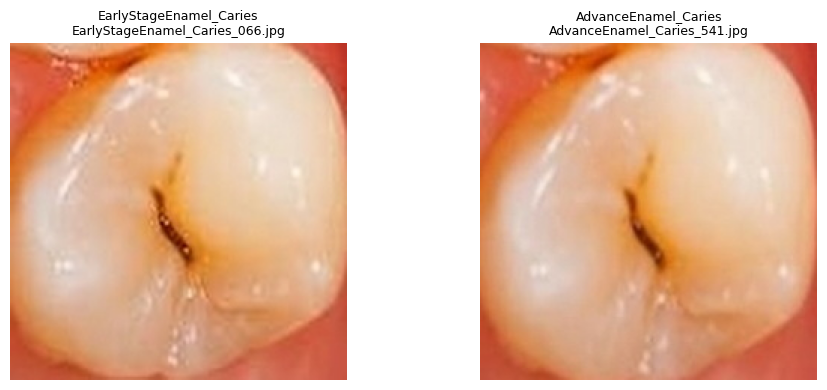

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

# Display the first cross-category group
group = cross_category_groups[0]

fig, axes = plt.subplots(
    1, len(group),
    figsize=(5 * len(group), 4)
)

if len(group) == 1:
    axes = [axes]

for ax, (category, filename) in zip(axes, group):
    image_path = dataset_path / category / filename

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(
        f"{category}\n{filename}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

conflicting_paths = set()

for group in cross_category_groups:
    for category, filename in group:
        conflicting_paths.add(
            str(dataset_path / category / filename)
        )

print("Conflicting groups:", len(cross_category_groups))
print("Images requiring review:", len(conflicting_paths))

for path in sorted(conflicting_paths):
    print(Path(path).relative_to(dataset_path))

Conflicting groups: 4
Images requiring review: 14
AdvanceEnamel_Caries/AdvanceEnamel_Caries_128.jpg
AdvanceEnamel_Caries/AdvanceEnamel_Caries_192.jpg
AdvanceEnamel_Caries/AdvanceEnamel_Caries_270.jpg
AdvanceEnamel_Caries/AdvanceEnamel_Caries_415.jpg
AdvanceEnamel_Caries/AdvanceEnamel_Caries_438.jpg
AdvanceEnamel_Caries/AdvanceEnamel_Caries_541.jpg
AdvanceEnamel_Caries/AdvanceEnamel_Caries_687.jpg
EarlyStageEnamel_Caries/EarlyStageEnamel_Caries_066.jpg
EarlyStageEnamel_Caries/EarlyStageEnamel_Caries_437.jpg
EarlyStageEnamel_Caries/EarlyStageEnamel_Caries_439.jpg
EarlyStageEnamel_Caries/EarlyStageEnamel_Caries_440.jpg
EarlyStageEnamel_Caries/EarlyStageEnamel_Caries_441.jpg
EarlyStageEnamel_Caries/EarlyStageEnamel_Caries_442.jpg
EarlyStageEnamel_Caries/EarlyStageEnamel_Caries_443.jpg


In [ ]:
import shutil
from pathlib import Path

clean_path = Path("/content/Caries_Cleaned")

categories = [
    "NoEnamel_Caries",
    "EarlyStageEnamel_Caries",
    "AdvanceEnamel_Caries"
]

for category in categories:
    source = dataset_path / category
    destination = clean_path / category
    destination.mkdir(parents=True, exist_ok=True)

    count = 0

    for image_path in source.iterdir():
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue

        if str(image_path) in conflicting_paths:
            continue

        shutil.copy2(image_path, destination / image_path.name)
        count += 1

    print(f"{category}: {count} images")

print("\nClean working dataset created!")
print("Location:", clean_path)

NoEnamel_Caries: 400 images
EarlyStageEnamel_Caries: 793 images
AdvanceEnamel_Caries: 793 images

Clean working dataset created!
Location: /content/Caries_Cleaned


In [ ]:
import random
import shutil
import imagehash
from PIL import Image
from pathlib import Path
from collections import defaultdict, Counter

random.seed(42)

split_path = Path("/content/Caries_Split")
clean_path = Path("/content/Caries_Cleaned")

categories = [
    "NoEnamel_Caries",
    "EarlyStageEnamel_Caries",
    "AdvanceEnamel_Caries"
]

for category in categories:
    files = sorted(
        p for p in (clean_path / category).iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    )

    # Group images with identical perceptual hashes
    groups = defaultdict(list)

    for path in files:
        with Image.open(path) as img:
            hash_value = str(imagehash.phash(img))
        groups[hash_value].append(path)

    group_list = list(groups.values())
    random.shuffle(group_list)

    train, valid, test = [], [], []

    for group in group_list:
        if len(train) < len(files) * 0.70:
            train.extend(group)
        elif len(valid) < len(files) * 0.15:
            valid.extend(group)
        else:
            test.extend(group)

    for split_name, images in [
        ("train", train),
        ("valid", valid),
        ("test", test)
    ]:
        destination = split_path / split_name / category
        destination.mkdir(parents=True, exist_ok=True)

        for image_path in images:
            shutil.copy2(
                image_path,
                destination / image_path.name
            )

        print(f"{split_name} / {category}: {len(images)}")

print("\nDataset splitting completed!")
print("Location:", split_path)

train / NoEnamel_Caries: 280
valid / NoEnamel_Caries: 60
test / NoEnamel_Caries: 60
train / EarlyStageEnamel_Caries: 556
valid / EarlyStageEnamel_Caries: 121
test / EarlyStageEnamel_Caries: 116
train / AdvanceEnamel_Caries: 559
valid / AdvanceEnamel_Caries: 119
test / AdvanceEnamel_Caries: 115

Dataset splitting completed!
Location: /content/Caries_Split


In [ ]:
from pathlib import Path
from collections import defaultdict
from PIL import Image
import imagehash

split_path = Path("/content/Caries_Split")

categories = [
    "NoEnamel_Caries",
    "EarlyStageEnamel_Caries",
    "AdvanceEnamel_Caries"
]

hash_splits = defaultdict(set)
total = 0

for split in ["train", "valid", "test"]:
    split_total = 0

    print(f"\n{split.upper()}:")

    for category in categories:
        folder = split_path / split / category
        images = sorted(
            p for p in folder.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        )

        print(f"  {category}: {len(images)}")
        split_total += len(images)

        for path in images:
            with Image.open(path) as img:
                h = str(imagehash.phash(img))
            hash_splits[h].add(split)

    print("Total:", split_total)
    total += split_total

leakage = sum(
    len(splits) > 1
    for splits in hash_splits.values()
)

print("\nOVERALL TOTAL:", total)
print("Expected total: 1986")
print("Identical perceptual hashes across splits:", leakage)

if total == 1986 and leakage == 0:
    print("Initial split verification PASSED!")
else:
    print("Split needs further checking.")


TRAIN:
  NoEnamel_Caries: 280
  EarlyStageEnamel_Caries: 556
  AdvanceEnamel_Caries: 559
Total: 1395

VALID:
  NoEnamel_Caries: 60
  EarlyStageEnamel_Caries: 121
  AdvanceEnamel_Caries: 119
Total: 300

TEST:
  NoEnamel_Caries: 60
  EarlyStageEnamel_Caries: 116
  AdvanceEnamel_Caries: 115
Total: 291

OVERALL TOTAL: 1986
Expected total: 1986
Identical perceptual hashes across splits: 0
Initial split verification PASSED!


In [ ]:
import shutil
from pathlib import Path

source = Path("/content/Caries_Split")

destination = Path(
    "/content/drive/MyDrive/Caries_Classification_Split"
)

zip_file = shutil.make_archive(
    str(destination),
    "zip",
    root_dir=source
)

print("Dataset backup completed!")
print("Saved to:", zip_file)
print(
    "File size:",
    round(Path(zip_file).stat().st_size / (1024**2), 2),
    "MB"
)

Dataset backup completed!
Saved to: /content/drive/MyDrive/Caries_Classification_Split.zip
File size: 23.68 MB


In [ ]:
from google.colab import drive
from pathlib import Path
import zipfile

drive.mount('/content/drive')

zip_path = Path(
    '/content/drive/MyDrive/Caries_Classification_Split.zip'
)

dataset_path = Path('/content/Caries_Split')

if not dataset_path.exists():
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(dataset_path)
    print("Dataset restored successfully!")
else:
    print("Dataset already available!")

print("Training folder:", (dataset_path / 'train').exists())
print("Validation folder:", (dataset_path / 'valid').exists())
print("Testing folder:", (dataset_path / 'test').exists())

Mounted at /content/drive
Dataset restored successfully!
Training folder: True
Validation folder: True
Testing folder: True


In [ ]:
import tensorflow as tf

# Training settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/Caries_Split/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

# Load validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/Caries_Split/valid",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

# Get class names
class_names = train_ds.class_names

print("\nClassification categories:")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")

print("\nTensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

Found 1395 files belonging to 3 classes.
Found 300 files belonging to 3 classes.

Classification categories:
0: AdvanceEnamel_Caries
1: EarlyStageEnamel_Caries
2: NoEnamel_Caries

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Input
inputs = layers.Input(shape=(224, 224, 3))

# Data augmentation (training only)
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)

# MobileNetV2 preprocessing
x = layers.Rescaling(1./127.5, offset=-1)(x)

# Pretrained feature extractor
x = base_model(x, training=False)

# Classification layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

model = Model(inputs, outputs)

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 model created successfully!")
print("Total parameters:", model.count_params())
print("Trainable parameters:",
      sum(
          tf.keras.backend.count_params(w)
          for w in model.trainable_weights
      ))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 model created successfully!
Total parameters: 2261827
Trainable parameters: 3843


In [ ]:
import tensorflow as tf
from pathlib import Path

# Folder for saving training results
save_dir = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/MobileNetV2"
)
save_dir.mkdir(parents=True, exist_ok=True)

# Save the best model based on validation loss
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(save_dir / "best_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Stop training when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

# Reduce learning rate when improvement slows
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

# Start training
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ]
)

print("\nMobileNetV2 training completed!")
print("Best model saved to:", save_dir / "best_model.keras")

Epoch 1/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5581 - loss: 0.9924
Epoch 1: val_loss improved from None to 0.54523, saving model to /content/drive/MyDrive/Dental_Caries_Results/MobileNetV2/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Dental_Caries_Results/MobileNetV2/best_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 14s 63ms/step - accuracy: 0.6487 - loss: 0.7835 - val_accuracy: 0.7833 - val_loss: 0.5452 - learning_rate: 0.0010
Epoch 2/15
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7952 - loss: 0.4965
Epoch 2: val_loss improved from 0.54523 to 0.43958, saving model to /content/drive/MyDrive/Dental_Caries_Results/MobileNetV2/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Dental_Caries_Results/MobileNetV2/best_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step - accuracy: 0.8014 - loss: 0.4886 - val_accuracy: 0.8167 - val_loss: 0.4396 - learning_rate: 0.0010
Epoch 3/15
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step

In [ ]:
import tensorflow as tf
from pathlib import Path

# Load the best saved model
model_path = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "MobileNetV2/best_model.keras"
)

best_model = tf.keras.models.load_model(model_path)

# Load test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/Caries_Split/test",
    image_size=(224, 224),
    batch_size=16,
    label_mode="categorical",
    shuffle=False
)

# Evaluate model
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\nMobileNetV2 Test Results")
print("------------------------")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Found 291 files belonging to 3 classes.
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.8763 - loss: 0.3050

MobileNetV2 Test Results
------------------------
Test Accuracy: 87.63%
Test Loss: 0.3050


19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 164ms/step

MobileNetV2 Classification Report
--------------------------------
                         precision    recall  f1-score   support

   AdvanceEnamel_Caries     0.9065    0.8435    0.8739       115
EarlyStageEnamel_Caries     0.8030    0.9138    0.8548       116
        NoEnamel_Caries     1.0000    0.8667    0.9286        60

               accuracy                         0.8763       291
              macro avg     0.9032    0.8746    0.8858       291
           weighted avg     0.8845    0.8763    0.8776       291



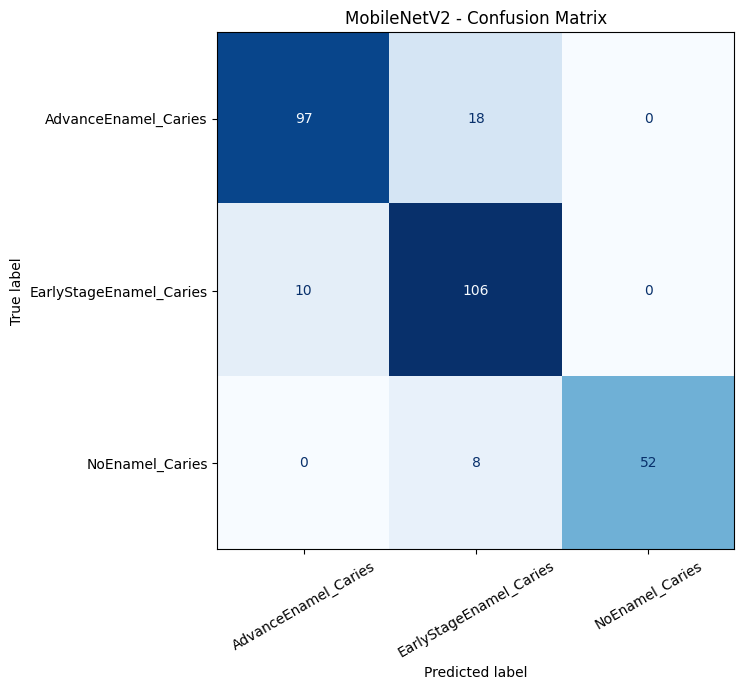

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Actual labels
y_true = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for images, labels in test_ds
])

# Model predictions
predictions = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(predictions, axis=1)

# Class names
class_names = test_ds.class_names

# Classification report
print("\nMobileNetV2 Classification Report")
print("--------------------------------")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
display_matrix.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=30,
    colorbar=False
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.tight_layout()

# Save figure to Google Drive
plt.savefig(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "MobileNetV2/confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from pathlib import Path
import json
import numpy as np
from sklearn.metrics import classification_report

save_dir = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/MobileNetV2"
)
save_dir.mkdir(parents=True, exist_ok=True)

# Generate evaluation report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

summary = {
    "model": "MobileNetV2",
    "training_images": 1395,
    "validation_images": 300,
    "test_images": 291,
    "test_accuracy": float(np.mean(y_true == y_pred)),
    "test_loss": float(test_loss),
    "classification_report": report,
    "confusion_matrix": cm.tolist(),
    "class_names": class_names
}

output_file = save_dir / "evaluation_results.json"

with open(output_file, "w") as f:
    json.dump(summary, f, indent=4)

print("MobileNetV2 evaluation results saved!")
print("Location:", output_file)

MobileNetV2 evaluation results saved!
Location: /content/drive/MyDrive/Dental_Caries_Results/MobileNetV2/evaluation_results.json


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

# Load pretrained EfficientNet-B0
efficientnet_base = EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
efficientnet_base.trainable = False

# Input layer
inputs = layers.Input(shape=(224, 224, 3))

# Data augmentation
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)

# EfficientNetB0 includes its own input rescaling.
# Do not apply MobileNetV2 preprocessing here.
x = efficientnet_base(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

efficientnet_model = Model(inputs, outputs)

# Compile model
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("EfficientNet-B0 model created successfully!")
print("Total parameters:", efficientnet_model.count_params())
print(
    "Trainable parameters:",
    sum(
        int(tf.size(w).numpy())
        for w in efficientnet_model.trainable_weights
    )
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNet-B0 model created successfully!
Total parameters: 4053414
Trainable parameters: 3843


In [ ]:
import tensorflow as tf
from pathlib import Path

# Create folder for EfficientNet-B0 results
save_dir = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/EfficientNetB0"
)
save_dir.mkdir(parents=True, exist_ok=True)

# Save the best model
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(save_dir / "best_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Stop training if validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

# Reduce learning rate when necessary
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

# Train EfficientNet-B0
efficientnet_history = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ]
)

print("\nEfficientNet-B0 training completed!")
print("Best model saved to:", save_dir / "best_model.keras")

Epoch 1/15
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.4920 - loss: 0.9788
Epoch 1: val_loss improved from None to 0.61580, saving model to /content/drive/MyDrive/Dental_Caries_Results/EfficientNetB0/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Dental_Caries_Results/EfficientNetB0/best_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 19s 91ms/step - accuracy: 0.6043 - loss: 0.8295 - val_accuracy: 0.7500 - val_loss: 0.6158 - learning_rate: 0.0010
Epoch 2/15
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.7594 - loss: 0.5607
Epoch 2: val_loss improved from 0.61580 to 0.52080, saving model to /content/drive/MyDrive/Dental_Caries_Results/EfficientNetB0/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Dental_Caries_Results/EfficientNetB0/best_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.7720 - loss: 0.5439 - val_accuracy: 0.7833 - val_loss: 0.5208 - learning_rate: 0.0010
Epoch 3/15
87/88 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
import tensorflow as tf
from pathlib import Path

# Load the best EfficientNet-B0 model
model_path = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "EfficientNetB0/best_model.keras"
)

best_efficientnet = tf.keras.models.load_model(model_path)

# Load the test dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/Caries_Split/test",
    image_size=(224, 224),
    batch_size=16,
    label_mode="categorical",
    shuffle=False
)

# Evaluate the model
test_loss_eff, test_accuracy_eff = best_efficientnet.evaluate(
    test_ds,
    verbose=1
)

print("\nEfficientNet-B0 Test Results")
print("---------------------------")
print(f"Test Accuracy: {test_accuracy_eff * 100:.2f}%")
print(f"Test Loss: {test_loss_eff:.4f}")

Found 291 files belonging to 3 classes.
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.8797 - loss: 0.3145

EfficientNet-B0 Test Results
---------------------------
Test Accuracy: 87.97%
Test Loss: 0.3145


19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 175ms/step

EfficientNet-B0 Classification Report
-----------------------------------
                         precision    recall  f1-score   support

   AdvanceEnamel_Caries     0.9000    0.8609    0.8800       115
EarlyStageEnamel_Caries     0.8240    0.8879    0.8548       116
        NoEnamel_Caries     0.9643    0.9000    0.9310        60

               accuracy                         0.8797       291
              macro avg     0.8961    0.8829    0.8886       291
           weighted avg     0.8830    0.8797    0.8805       291



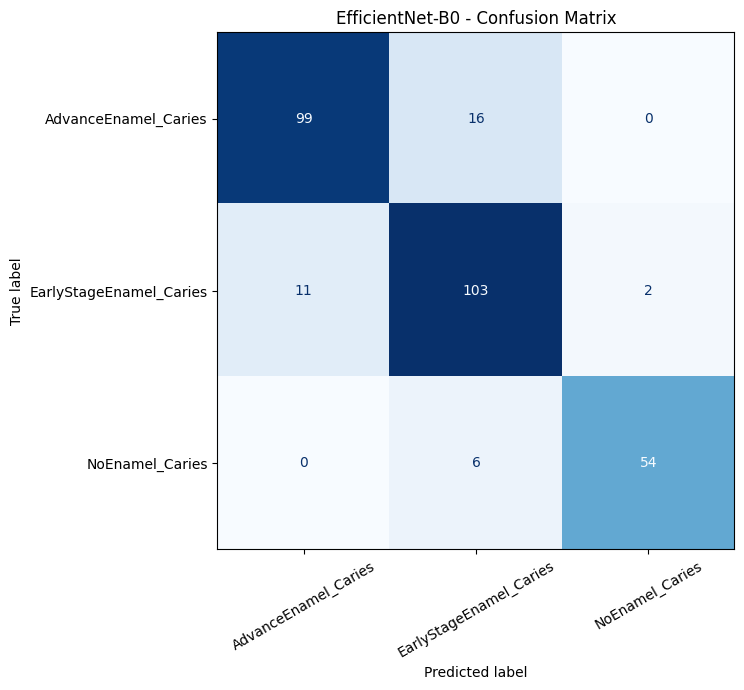

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Actual labels
y_true_eff = np.concatenate([
    np.argmax(labels.numpy(), axis=1)
    for images, labels in test_ds
])

# EfficientNet-B0 predictions
predictions_eff = best_efficientnet.predict(
    test_ds,
    verbose=1
)

y_pred_eff = np.argmax(predictions_eff, axis=1)

# Class names
class_names = test_ds.class_names

# Classification report
print("\nEfficientNet-B0 Classification Report")
print("-----------------------------------")

print(classification_report(
    y_true_eff,
    y_pred_eff,
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm_eff = confusion_matrix(y_true_eff, y_pred_eff)

fig, ax = plt.subplots(figsize=(9, 7))

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm_eff,
    display_labels=class_names
)

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=30,
    colorbar=False
)

plt.title("EfficientNet-B0 - Confusion Matrix")
plt.tight_layout()

# Save to Google Drive
plt.savefig(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "EfficientNetB0/confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from pathlib import Path
import json
import numpy as np
from sklearn.metrics import classification_report

save_dir = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/EfficientNetB0"
)
save_dir.mkdir(parents=True, exist_ok=True)

report = classification_report(
    y_true_eff,
    y_pred_eff,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

summary = {
    "model": "EfficientNet-B0",
    "training_images": 1395,
    "validation_images": 300,
    "test_images": 291,
    "test_accuracy": float(np.mean(y_true_eff == y_pred_eff)),
    "test_loss": float(test_loss_eff),
    "classification_report": report,
    "confusion_matrix": cm_eff.tolist(),
    "class_names": class_names
}

output_file = save_dir / "evaluation_results.json"

with open(output_file, "w") as f:
    json.dump(summary, f, indent=4)

print("EfficientNet-B0 evaluation results saved!")
print("Location:", output_file)

EfficientNet-B0 evaluation results saved!
Location: /content/drive/MyDrive/Dental_Caries_Results/EfficientNetB0/evaluation_results.json


In [ ]:
import tensorflow as tf
from pathlib import Path

# Load the saved MobileNetV2 model
model_path = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "MobileNetV2/best_model.keras"
)

gradcam_model = tf.keras.models.load_model(model_path)

# Display the model's layers
print("MobileNetV2 model layers:")
print("-----------------------")

for index, layer in enumerate(gradcam_model.layers):
    print(index, layer.name, layer.__class__.__name__)

# Find the nested MobileNetV2 feature extractor
base_models = [
    layer for layer in gradcam_model.layers
    if isinstance(layer, tf.keras.Model)
]

print("\nNested feature extractors:")

for base in base_models:
    print("Name:", base.name)
    print("Last layer:", base.layers[-1].name)
    print("Output shape:", base.output.shape)

MobileNetV2 model layers:
-----------------------
0 input_layer_1 InputLayer
1 random_flip RandomFlip
2 random_rotation RandomRotation
3 rescaling Rescaling
4 mobilenetv2_1.00_224 Functional
5 global_average_pooling2d GlobalAveragePooling2D
6 dropout Dropout
7 dense Dense

Nested feature extractors:
Name: mobilenetv2_1.00_224
Last layer: out_relu
Output shape: (None, 7, 7, 1280)


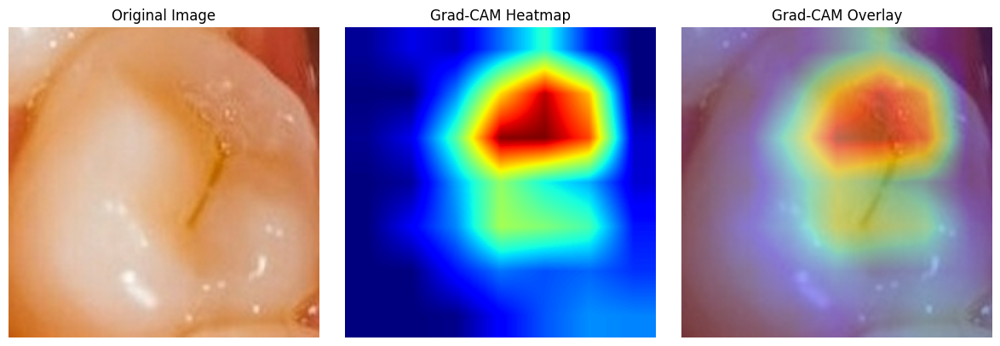

Image: EarlyStageEnamel_Caries_002.jpg
Predicted class: EarlyStageEnamel_Caries
Confidence: 93.67 %
Grad-CAM saved to: /content/drive/MyDrive/Dental_Caries_Results/MobileNetV2/gradcam_sample.png


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Reuse the trained MobileNetV2 model
model = gradcam_model

# Select one test image
test_folder = Path(
    "/content/Caries_Split/test/EarlyStageEnamel_Caries"
)

image_path = sorted(test_folder.glob("*.jpg"))[0]

# Load the image
original = Image.open(image_path).convert("RGB")
resized = original.resize((224, 224))

image_array = np.array(resized, dtype=np.float32)
image_batch = tf.expand_dims(image_array, axis=0)

# Get model layers
augmentation_flip = model.get_layer("random_flip")
augmentation_rotation = model.get_layer("random_rotation")
rescaling = model.get_layer("rescaling")
base_model = model.get_layer("mobilenetv2_1.00_224")
pooling = model.get_layer("global_average_pooling2d")
dropout = model.get_layer("dropout")
classifier = model.get_layer("dense")

# Apply the same preprocessing used during training
x = augmentation_flip(image_batch, training=False)
x = augmentation_rotation(x, training=False)
x = rescaling(x)

# Calculate Grad-CAM
with tf.GradientTape() as tape:
    feature_maps = base_model(x, training=False)
    tape.watch(feature_maps)

    x = pooling(feature_maps)
    x = dropout(x, training=False)
    predictions = classifier(x)

    predicted_class = tf.argmax(predictions[0])
    class_score = predictions[:, predicted_class]

gradients = tape.gradient(class_score, feature_maps)

# Calculate importance weights
weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

heatmap = tf.reduce_sum(
    feature_maps[0] * weights,
    axis=-1
)

heatmap = tf.maximum(heatmap, 0)

# Normalize heatmap
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

heatmap = tf.image.resize(
    heatmap[..., tf.newaxis],
    (224, 224)
).numpy().squeeze()

# Create overlay
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(resized)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet", vmin=0, vmax=1)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(resized)
plt.imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()

# Save visualization to Google Drive
save_path = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "MobileNetV2/gradcam_sample.png"
)

plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()

print("Image:", image_path.name)
print("Predicted class:", class_names[int(predicted_class.numpy())])
print("Confidence:", round(
    float(tf.reduce_max(predictions).numpy()) * 100, 2
), "%")
print("Grad-CAM saved to:", save_path)

In [ ]:
import tensorflow as tf
from pathlib import Path

model_path = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "EfficientNetB0/best_model.keras"
)

efficient_gradcam_model = tf.keras.models.load_model(
    model_path
)

print("EfficientNet-B0 model layers:")
print("---------------------------")

for index, layer in enumerate(efficient_gradcam_model.layers):
    print(index, layer.name, layer.__class__.__name__)

print("\nNested feature extractors:")

for layer in efficient_gradcam_model.layers:
    if isinstance(layer, tf.keras.Model):
        print("Name:", layer.name)
        print("Last layer:", layer.layers[-1].name)
        print("Output shape:", layer.output.shape)

EfficientNet-B0 model layers:
---------------------------
0 input_layer_3 InputLayer
1 random_flip_1 RandomFlip
2 random_rotation_1 RandomRotation
3 efficientnetb0 Functional
4 global_average_pooling2d_1 GlobalAveragePooling2D
5 dropout_1 Dropout
6 dense_1 Dense

Nested feature extractors:
Name: efficientnetb0
Last layer: top_activation
Output shape: (None, 7, 7, 1280)


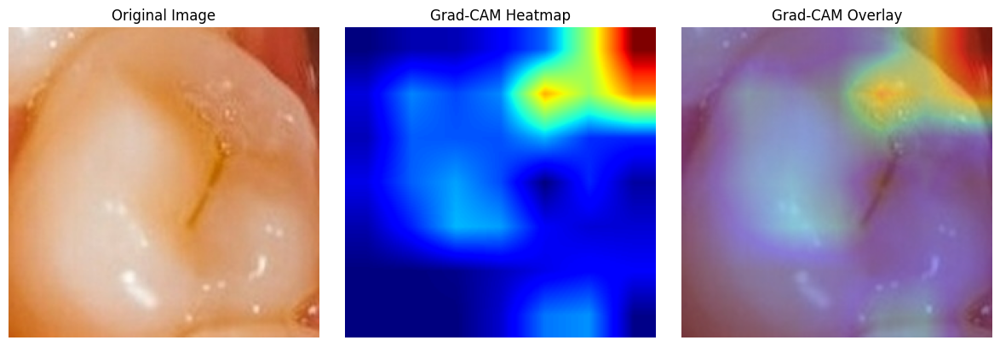

Image: EarlyStageEnamel_Caries_002.jpg
Predicted class: EarlyStageEnamel_Caries
Confidence: 80.69 %
Grad-CAM saved to: /content/drive/MyDrive/Dental_Caries_Results/EfficientNetB0/gradcam_sample.png


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Use the loaded EfficientNet-B0 model
model = efficient_gradcam_model

# Use the same image as before
image_path = Path(
    "/content/Caries_Split/test/EarlyStageEnamel_Caries/EarlyStageEnamel_Caries_002.jpg"
)

# Load image
original = Image.open(image_path).convert("RGB")
resized = original.resize((224, 224))

image_array = np.array(resized, dtype=np.float32)
image_batch = tf.expand_dims(image_array, axis=0)

# Get model layers
augmentation_flip = model.get_layer("random_flip_1")
augmentation_rotation = model.get_layer("random_rotation_1")
base_model = model.get_layer("efficientnetb0")
pooling = model.get_layer("global_average_pooling2d_1")
dropout = model.get_layer("dropout_1")
classifier = model.get_layer("dense_1")

# Apply same preprocessing path used in model
x = augmentation_flip(image_batch, training=False)
x = augmentation_rotation(x, training=False)

# Grad-CAM
with tf.GradientTape() as tape:
    feature_maps = base_model(x, training=False)
    tape.watch(feature_maps)

    x = pooling(feature_maps)
    x = dropout(x, training=False)
    predictions = classifier(x)

    predicted_class = tf.argmax(predictions[0])
    class_score = predictions[:, predicted_class]

gradients = tape.gradient(class_score, feature_maps)

# Channel importance
weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

heatmap = tf.reduce_sum(feature_maps[0] * weights, axis=-1)
heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

heatmap = tf.image.resize(
    heatmap[..., tf.newaxis],
    (224, 224)
).numpy().squeeze()

# Show results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(resized)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet", vmin=0, vmax=1)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(resized)
plt.imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()

# Save to Google Drive
save_path = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "EfficientNetB0/gradcam_sample.png"
)

plt.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()

print("Image:", image_path.name)
print("Predicted class:", class_names[int(predicted_class.numpy())])
print("Confidence:", round(float(tf.reduce_max(predictions).numpy()) * 100, 2), "%")
print("Grad-CAM saved to:", save_path)

In [ ]:
import json
from pathlib import Path

results_dir = Path(
    "/content/drive/MyDrive/Dental_Caries_Results"
)

comparison = {
    "dataset": "Caries-Spectra",
    "classes": [
        "AdvanceEnamel_Caries",
        "EarlyStageEnamel_Caries",
        "NoEnamel_Caries"
    ],
    "training_images": 1395,
    "validation_images": 300,
    "test_images": 291,

    "MobileNetV2": {
        "accuracy": 0.8763,
        "weighted_f1": 0.8776,
        "test_loss": 0.3050,
        "gradcam": "Completed"
    },

    "EfficientNetB0": {
        "accuracy": 0.8797,
        "weighted_f1": 0.8805,
        "test_loss": 0.3145,
        "gradcam": "Completed"
    },

    "research_note": (
        "Both models achieved similar results on the "
        "image-level test split. Further independent "
        "validation is required before clinical use."
    )
}

output_path = results_dir / "Classification_Model_Comparison.json"

with open(output_path, "w") as file:
    json.dump(comparison, file, indent=4)

print("Model comparison saved successfully!")
print("Location:", output_path)

Model comparison saved successfully!
Location: /content/drive/MyDrive/Dental_Caries_Results/Classification_Model_Comparison.json


In [ ]:
from pathlib import Path
import zipfile

# YOLOv8 model saved in Google Drive
yolo_model_path = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "YOLOv8_First_Training/weights/best.pt"
)

# Cleaned YOLOv8 dataset backup
yolo_zip = Path(
    "/content/drive/MyDrive/YOLO_Caries_Cleaned.zip"
)

# Working dataset location
yolo_dataset_path = Path(
    "/content/YOLO_Caries_Training"
)

# Check saved files
print("YOLOv8 model found:", yolo_model_path.exists())
print("YOLO dataset ZIP found:", yolo_zip.exists())

# Restore dataset if necessary
if yolo_zip.exists() and not yolo_dataset_path.exists():
    with zipfile.ZipFile(yolo_zip, "r") as zip_ref:
        zip_ref.extractall("/content")

    print("YOLOv8 dataset restored!")

print("YOLO dataset folder found:", yolo_dataset_path.exists())

# Check available test images
test_folder = yolo_dataset_path / "images/test"

if test_folder.exists():
    images = list(test_folder.glob("*.jpg"))
    images += list(test_folder.glob("*.png"))
    images += list(test_folder.glob("*.jpeg"))

    print("YOLO test images:", len(images))

YOLOv8 model found: True
YOLO dataset ZIP found: True
YOLOv8 dataset restored!
YOLO dataset folder found: True
YOLO test images: 230


In [ ]:
from ultralytics import YOLO
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

# Load trained YOLOv8 model
yolo_model = YOLO(str(yolo_model_path))

# Select the same test image used previously
image_path = Path(
    "/content/YOLO_Caries_Training/images/test/"
    "anonymous-maxillaryView-1726818272842.jpg"
)

# Run detection
results = yolo_model.predict(
    source=str(image_path),
    conf=0.25,
    verbose=False
)

# Load original image
original = Image.open(image_path).convert("RGB")

# Display YOLOv8 detections
annotated = results[0].plot()

plt.figure(figsize=(10, 6))
plt.imshow(annotated[:, :, ::-1])
plt.title("YOLOv8 Caries Detections")
plt.axis("off")
plt.show()

# Crop detected regions
boxes = results[0].boxes.xyxy.cpu().numpy()

print("Total detected regions:", len(boxes))

fig, axes = plt.subplots(
    1, len(boxes),
    figsize=(3 * len(boxes), 3)
)

if len(boxes) == 1:
    axes = [axes]

for i, box in enumerate(boxes):
    x1, y1, x2, y2 = map(int, box)

    cropped = original.crop((x1, y1, x2, y2))

    axes[i].imshow(cropped)
    axes[i].set_title(f"Region {i + 1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 11.2 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

print("Ultralytics installed successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics installed successfully!


In [ ]:
from ultralytics import YOLO
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

# Load trained YOLOv8 model
yolo_model = YOLO(str(yolo_model_path))

# Select the same test image used previously
image_path = Path(
    "/content/YOLO_Caries_Training/images/test/"
    "anonymous-maxillaryView-1726818272842.jpg"
)

# Run detection
results = yolo_model.predict(
    source=str(image_path),
    conf=0.25,
    verbose=False
)

# Load original image
original = Image.open(image_path).convert("RGB")

# Display YOLOv8 detections
annotated = results[0].plot()

plt.figure(figsize=(10, 6))
plt.imshow(annotated[:, :, ::-1])
plt.title("YOLOv8 Caries Detections")
plt.axis("off")
plt.show()

# Crop detected regions
boxes = results[0].boxes.xyxy.cpu().numpy()

print("Total detected regions:", len(boxes))

fig, axes = plt.subplots(
    1, len(boxes),
    figsize=(3 * len(boxes), 3)
)

if len(boxes) == 1:
    axes = [axes]

for i, box in enumerate(boxes):
    x1, y1, x2, y2 = map(int, box)

    cropped = original.crop((x1, y1, x2, y2))

    axes[i].imshow(cropped)
    axes[i].set_title(f"Region {i + 1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

NameError: name 'yolo_model_path' is not defined

In [ ]:
from pathlib import Path
from ultralytics import YOLO

# Define the saved YOLOv8 model path
yolo_model_path = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "YOLOv8_First_Training/weights/best.pt"
)

# Check whether the model exists
print("Model found:", yolo_model_path.exists())

# Load the trained model
if yolo_model_path.exists():
    yolo_model = YOLO(str(yolo_model_path))
    print("YOLOv8 model loaded successfully!")
else:
    print("Model not found. Check Google Drive connection.")

Model found: True
YOLOv8 model loaded successfully!


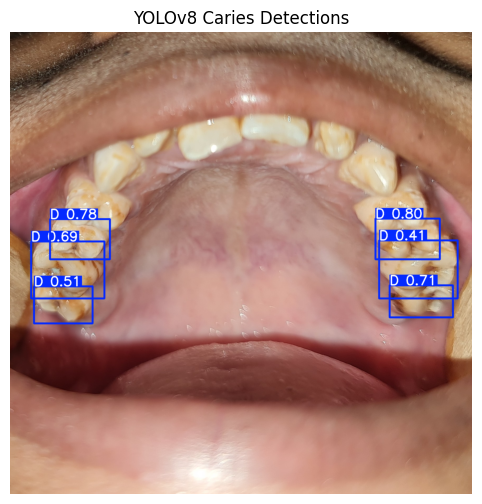

Total detected regions: 6


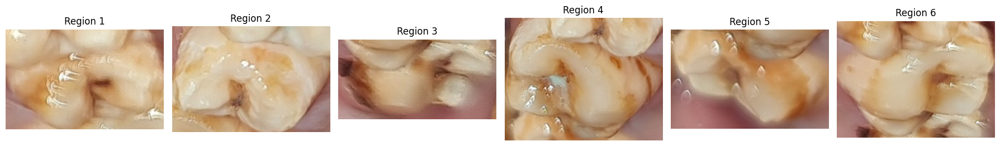

In [ ]:
from ultralytics import YOLO
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt

# Load trained YOLOv8 model
yolo_model = YOLO(str(yolo_model_path))

# Select the same test image used previously
image_path = Path(
    "/content/YOLO_Caries_Training/images/test/"
    "anonymous-maxillaryView-1726818272842.jpg"
)

# Run detection
results = yolo_model.predict(
    source=str(image_path),
    conf=0.25,
    verbose=False
)

# Load original image
original = Image.open(image_path).convert("RGB")

# Display YOLOv8 detections
annotated = results[0].plot()

plt.figure(figsize=(10, 6))
plt.imshow(annotated[:, :, ::-1])
plt.title("YOLOv8 Caries Detections")
plt.axis("off")
plt.show()

# Crop detected regions
boxes = results[0].boxes.xyxy.cpu().numpy()

print("Total detected regions:", len(boxes))

fig, axes = plt.subplots(
    1, len(boxes),
    figsize=(3 * len(boxes), 3)
)

if len(boxes) == 1:
    axes = [axes]

for i, box in enumerate(boxes):
    x1, y1, x2, y2 = map(int, box)

    cropped = original.crop((x1, y1, x2, y2))

    axes[i].imshow(cropped)
    axes[i].set_title(f"Region {i + 1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

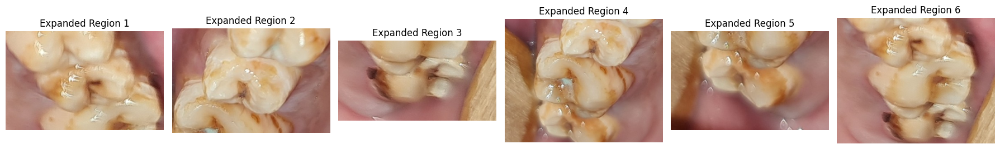

Expanded crops created: 6


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# Use the existing YOLO results and original image
original = Image.open(image_path).convert("RGB")

width, height = original.size

expanded_crops = []

for box in boxes:
    x1, y1, x2, y2 = box

    # Original bounding box dimensions
    box_width = x2 - x1
    box_height = y2 - y1

    # Expand bounding box by 30% on each side
    padding_x = box_width * 0.30
    padding_y = box_height * 0.30

    new_x1 = max(0, int(x1 - padding_x))
    new_y1 = max(0, int(y1 - padding_y))
    new_x2 = min(width, int(x2 + padding_x))
    new_y2 = min(height, int(y2 + padding_y))

    # Crop expanded region
    crop = original.crop(
        (new_x1, new_y1, new_x2, new_y2)
    )

    expanded_crops.append(crop)

# Display expanded regions
fig, axes = plt.subplots(
    1,
    len(expanded_crops),
    figsize=(18, 4)
)

if len(expanded_crops) == 1:
    axes = [axes]

for i, crop in enumerate(expanded_crops):
    axes[i].imshow(crop)
    axes[i].set_title(f"Expanded Region {i + 1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

print("Expanded crops created:", len(expanded_crops))

In [ ]:
import tensorflow as tf
import numpy as np
from pathlib import Path

# Load saved classification models
mobile_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "MobileNetV2/best_model.keras"
)

efficient_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "EfficientNetB0/best_model.keras"
)

# Use the same class order established during training
class_names = [
    "AdvanceEnamel_Caries",
    "EarlyStageEnamel_Caries",
    "NoEnamel_Caries"
]

# Prepare expanded crops
crop_arrays = []

for crop in expanded_crops:
    resized = crop.resize((224, 224))
    crop_arrays.append(
        np.asarray(resized, dtype=np.float32)
    )

crop_batch = np.stack(crop_arrays)

# Both models receive RGB images in the 0–255 range.
# Their saved architectures handle preprocessing internally.
mobile_predictions = mobile_model.predict(
    crop_batch, verbose=0
)

efficient_predictions = efficient_model.predict(
    crop_batch, verbose=0
)

print("YOLOv8 + Severity Classification Results")
print("--------------------------------------")

for i in range(len(expanded_crops)):
    mobile_index = np.argmax(mobile_predictions[i])
    efficient_index = np.argmax(efficient_predictions[i])

    print(f"\nRegion {i + 1}")

    print(
        "MobileNetV2:",
        class_names[mobile_index],
        f"({mobile_predictions[i][mobile_index] * 100:.2f}%)"
    )

    print(
        "EfficientNet-B0:",
        class_names[efficient_index],
        f"({efficient_predictions[i][efficient_index] * 100:.2f}%)"
    )

YOLOv8 + Severity Classification Results
--------------------------------------

Region 1
MobileNetV2: AdvanceEnamel_Caries (98.57%)
EfficientNet-B0: AdvanceEnamel_Caries (86.86%)

Region 2
MobileNetV2: AdvanceEnamel_Caries (91.07%)
EfficientNet-B0: AdvanceEnamel_Caries (84.21%)

Region 3
MobileNetV2: AdvanceEnamel_Caries (99.90%)
EfficientNet-B0: AdvanceEnamel_Caries (94.06%)

Region 4
MobileNetV2: AdvanceEnamel_Caries (99.73%)
EfficientNet-B0: AdvanceEnamel_Caries (94.42%)

Region 5
MobileNetV2: AdvanceEnamel_Caries (97.48%)
EfficientNet-B0: AdvanceEnamel_Caries (64.47%)

Region 6
MobileNetV2: AdvanceEnamel_Caries (99.93%)
EfficientNet-B0: AdvanceEnamel_Caries (94.49%)


In [ ]:
from pathlib import Path
from collections import Counter
import numpy as np

# Find YOLOv8 test images
test_folder = Path(
    "/content/YOLO_Caries_Training/images/test"
)

image_files = sorted([
    p for p in test_folder.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

# Select five reproducible test images
rng = np.random.default_rng(42)
selected = rng.choice(
    len(image_files),
    size=min(5, len(image_files)),
    replace=False
)

mobile_counts = Counter()
efficient_counts = Counter()

for index in selected:
    image_path = image_files[index]

    # Run YOLOv8 detection
    result = yolo_model.predict(
        str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    crops = []

    for box in result.boxes.xyxy.cpu().numpy():
        x1, y1, x2, y2 = box

        pad_x = (x2 - x1) * 0.30
        pad_y = (y2 - y1) * 0.30

        crop = image.crop((
            max(0, int(x1 - pad_x)),
            max(0, int(y1 - pad_y)),
            min(width, int(x2 + pad_x)),
            min(height, int(y2 + pad_y))
        ))

        crops.append(
            np.asarray(
                crop.resize((224, 224)),
                dtype=np.float32
            )
        )

    if not crops:
        print(image_path.name, "No detections")
        continue

    batch = np.stack(crops)

    mobile_preds = mobile_model.predict(
        batch, verbose=0
    ).argmax(axis=1)

    efficient_preds = efficient_model.predict(
        batch, verbose=0
    ).argmax(axis=1)

    for p in mobile_preds:
        mobile_counts[class_names[p]] += 1

    for p in efficient_preds:
        efficient_counts[class_names[p]] += 1

    print(
        image_path.name,
        "| Regions:", len(crops)
    )

print("\nMobileNetV2 prediction distribution:")
print(dict(mobile_counts))

print("\nEfficientNet-B0 prediction distribution:")
print(dict(efficient_counts))

anonymous_003-009-1197-01_1732783016757_Mandibular_View.jpg | Regions: 3
anonymous_003-008-1119-01_1732368732116_Mandibular_View.jpg | Regions: 4
anonymous_003-008-801-00_1729865168164_Mandibular_View.jpg | Regions: 5
anonymous-maxillaryView-1727759978916.jpg | Regions: 1
anonymous_003-008-1104-00_1732272483924_Mandibular_View.jpg | Regions: 4

MobileNetV2 prediction distribution:
{'AdvanceEnamel_Caries': 15, 'EarlyStageEnamel_Caries': 2}

EfficientNet-B0 prediction distribution:
{'AdvanceEnamel_Caries': 15, 'EarlyStageEnamel_Caries': 2}


In [ ]:
import numpy as np

agreements = 0
total_regions = 0

for index in selected:
    image_path = image_files[index]

    result = yolo_model.predict(
        str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    crops = []

    for box in result.boxes.xyxy.cpu().numpy():
        x1, y1, x2, y2 = box

        pad_x = (x2 - x1) * 0.30
        pad_y = (y2 - y1) * 0.30

        crop = image.crop((
            max(0, int(x1 - pad_x)),
            max(0, int(y1 - pad_y)),
            min(width, int(x2 + pad_x)),
            min(height, int(y2 + pad_y))
        ))

        crops.append(
            np.asarray(
                crop.resize((224, 224)),
                dtype=np.float32
            )
        )

    if not crops:
        continue

    batch = np.stack(crops)

    mobile_preds = mobile_model.predict(
        batch, verbose=0
    ).argmax(axis=1)

    efficient_preds = efficient_model.predict(
        batch, verbose=0
    ).argmax(axis=1)

    agreements += np.sum(
        mobile_preds == efficient_preds
    )

    total_regions += len(crops)

print("Total regions compared:", total_regions)
print("Matching predictions:", agreements)
print("Different predictions:", total_regions - agreements)
print(
    "Agreement percentage:",
    round(agreements / total_regions * 100, 2),
    "%"
)

Total regions compared: 17
Matching predictions: 15
Different predictions: 2
Agreement percentage: 88.24 %


Disagreement regions found: 2


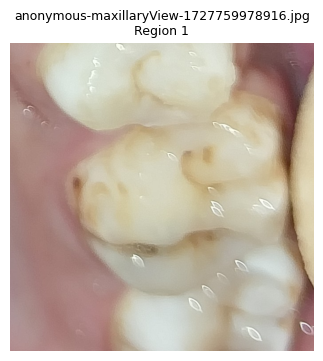

MobileNetV2: EarlyStageEnamel_Caries (74.74%)
EfficientNet-B0: AdvanceEnamel_Caries (54.29%)



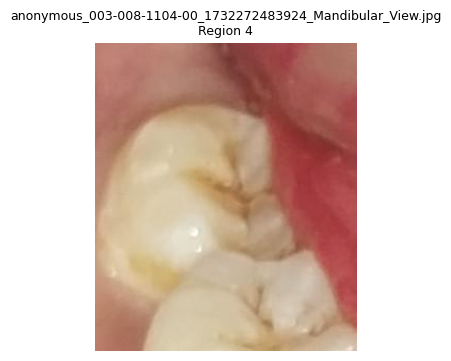

MobileNetV2: AdvanceEnamel_Caries (95.96%)
EfficientNet-B0: EarlyStageEnamel_Caries (47.93%)



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

disagreements = []

for index in selected:
    img_path = image_files[index]

    result = yolo_model.predict(
        str(img_path), conf=0.25, verbose=False
    )[0]

    image = Image.open(img_path).convert("RGB")
    width, height = image.size
    crops = []

    for box in result.boxes.xyxy.cpu().numpy():
        x1, y1, x2, y2 = box
        px = (x2 - x1) * 0.30
        py = (y2 - y1) * 0.30

        crop = image.crop((
            max(0, int(x1 - px)),
            max(0, int(y1 - py)),
            min(width, int(x2 + px)),
            min(height, int(y2 + py))
        ))
        crops.append(crop)

    if not crops:
        continue

    batch = np.stack([
        np.asarray(c.resize((224, 224)), dtype=np.float32)
        for c in crops
    ])

    mobile_probs = mobile_model.predict(batch, verbose=0)
    efficient_probs = efficient_model.predict(batch, verbose=0)

    for i, crop in enumerate(crops):
        m = int(np.argmax(mobile_probs[i]))
        e = int(np.argmax(efficient_probs[i]))

        if m != e:
            disagreements.append((
                crop, img_path.name, i + 1,
                class_names[m], float(mobile_probs[i, m]),
                class_names[e], float(efficient_probs[i, e])
            ))

print("Disagreement regions found:", len(disagreements))

for crop, filename, region, m_class, m_conf, e_class, e_conf in disagreements:
    plt.figure(figsize=(4, 4))
    plt.imshow(crop)
    plt.title(f"{filename}\nRegion {region}", fontsize=9)
    plt.axis("off")
    plt.show()

    print(f"MobileNetV2: {m_class} ({m_conf:.2%})")
    print(f"EfficientNet-B0: {e_class} ({e_conf:.2%})")
    print()

In [ ]:
import json
from pathlib import Path

save_dir = Path(
    "/content/drive/MyDrive/Dental_Caries_Results"
)

records = []

for crop, filename, region, m_class, m_conf, e_class, e_conf in disagreements:
    records.append({
        "image": filename,
        "region": int(region),
        "MobileNetV2_prediction": m_class,
        "MobileNetV2_confidence": round(float(m_conf), 4),
        "EfficientNetB0_prediction": e_class,
        "EfficientNetB0_confidence": round(float(e_conf), 4),
        "status": "Uncertain - Review Required"
    })

output_path = save_dir / "Integration_Disagreements.json"

with open(output_path, "w") as f:
    json.dump(records, f, indent=4)

print("Disagreement analysis saved!")
print("Regions requiring review:", len(records))
print("File:", output_path)

Disagreement analysis saved!
Regions requiring review: 2
File: /content/drive/MyDrive/Dental_Caries_Results/Integration_Disagreements.json


In [ ]:
import numpy as np
from PIL import Image
from pathlib import Path

def predict_dental_caries(image_path):
    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    # Step 1: YOLOv8 detection
    detection = yolo_model.predict(
        str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    boxes = detection.boxes.xyxy.cpu().numpy()
    detection_confidences = detection.boxes.conf.cpu().numpy()

    if len(boxes) == 0:
        return {
            "image": Path(image_path).name,
            "regions": [],
            "message": "No suspected regions detected"
        }

    crops = []

    # Step 2: Expand detected bounding boxes
    for box in boxes:
        x1, y1, x2, y2 = box

        pad_x = (x2 - x1) * 0.30
        pad_y = (y2 - y1) * 0.30

        crop = image.crop((
            max(0, int(x1 - pad_x)),
            max(0, int(y1 - pad_y)),
            min(width, int(x2 + pad_x)),
            min(height, int(y2 + pad_y))
        ))

        crops.append(
            np.asarray(
                crop.resize((224, 224)),
                dtype=np.float32
            )
        )

    batch = np.stack(crops)

    # Step 3: Severity classification
    mobile_probs = mobile_model.predict(
        batch, verbose=0
    )

    efficient_probs = efficient_model.predict(
        batch, verbose=0
    )

    region_results = []

    # Step 4: Compare predictions
    for i in range(len(boxes)):
        m_index = int(np.argmax(mobile_probs[i]))
        e_index = int(np.argmax(efficient_probs[i]))

        mobile_class = class_names[m_index]
        efficient_class = class_names[e_index]

        if mobile_class == efficient_class:
            status = "Agreement"
            final_prediction = mobile_class
        else:
            status = "Uncertain - Review Required"
            final_prediction = "Uncertain"

        region_results.append({
            "region": i + 1,
            "bounding_box": boxes[i].astype(int).tolist(),
            "detection_confidence": round(
                float(detection_confidences[i]), 4
            ),
            "MobileNetV2": {
                "prediction": mobile_class,
                "confidence": round(
                    float(mobile_probs[i, m_index]), 4
                )
            },
            "EfficientNetB0": {
                "prediction": efficient_class,
                "confidence": round(
                    float(efficient_probs[i, e_index]), 4
                )
            },
            "status": status,
            "final_prediction": final_prediction
        })

    return {
        "image": Path(image_path).name,
        "regions": region_results,
        "total_regions": len(region_results)
    }

print("Combined prediction function created successfully!")

Combined prediction function created successfully!


In [ ]:
import json
from pathlib import Path

# Select a dental test image
test_image = Path(
    "/content/YOLO_Caries_Training/images/test/"
    "anonymous-maxillaryView-1726818272842.jpg"
)

# Run the complete prediction pipeline
final_results = predict_dental_caries(test_image)

# Display results
print("Dental Caries Detection and Severity Assessment")
print("-----------------------------------------------")

print("Image:", final_results["image"])
print("Detected regions:", len(final_results["regions"]))

for region in final_results["regions"]:
    print(f"\nRegion {region['region']}")
    print("YOLOv8 confidence:", region["detection_confidence"])
    print("MobileNetV2:", region["MobileNetV2"]["prediction"])
    print("EfficientNet-B0:", region["EfficientNetB0"]["prediction"])
    print("Status:", region["status"])
    print("Final prediction:", region["final_prediction"])

# Save results to Google Drive
save_dir = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/Integration"
)

save_dir.mkdir(parents=True, exist_ok=True)

output_path = save_dir / "combined_prediction_results.json"

with open(output_path, "w") as f:
    json.dump(final_results, f, indent=4)

print("\nCombined prediction results saved!")
print("Location:", output_path)

Dental Caries Detection and Severity Assessment
-----------------------------------------------
Image: anonymous-maxillaryView-1726818272842.jpg
Detected regions: 6

Region 1
YOLOv8 confidence: 0.8006
MobileNetV2: AdvanceEnamel_Caries
EfficientNet-B0: AdvanceEnamel_Caries
Status: Agreement
Final prediction: AdvanceEnamel_Caries

Region 2
YOLOv8 confidence: 0.7833
MobileNetV2: AdvanceEnamel_Caries
EfficientNet-B0: AdvanceEnamel_Caries
Status: Agreement
Final prediction: AdvanceEnamel_Caries

Region 3
YOLOv8 confidence: 0.7051
MobileNetV2: AdvanceEnamel_Caries
EfficientNet-B0: AdvanceEnamel_Caries
Status: Agreement
Final prediction: AdvanceEnamel_Caries

Region 4
YOLOv8 confidence: 0.6913
MobileNetV2: AdvanceEnamel_Caries
EfficientNet-B0: AdvanceEnamel_Caries
Status: Agreement
Final prediction: AdvanceEnamel_Caries

Region 5
YOLOv8 confidence: 0.5122
MobileNetV2: AdvanceEnamel_Caries
EfficientNet-B0: AdvanceEnamel_Caries
Status: Agreement
Final prediction: AdvanceEnamel_Caries

Region 6


Annotated prediction saved successfully!
Location: /content/drive/MyDrive/Dental_Caries_Results/Integration/annotated_prediction.jpg


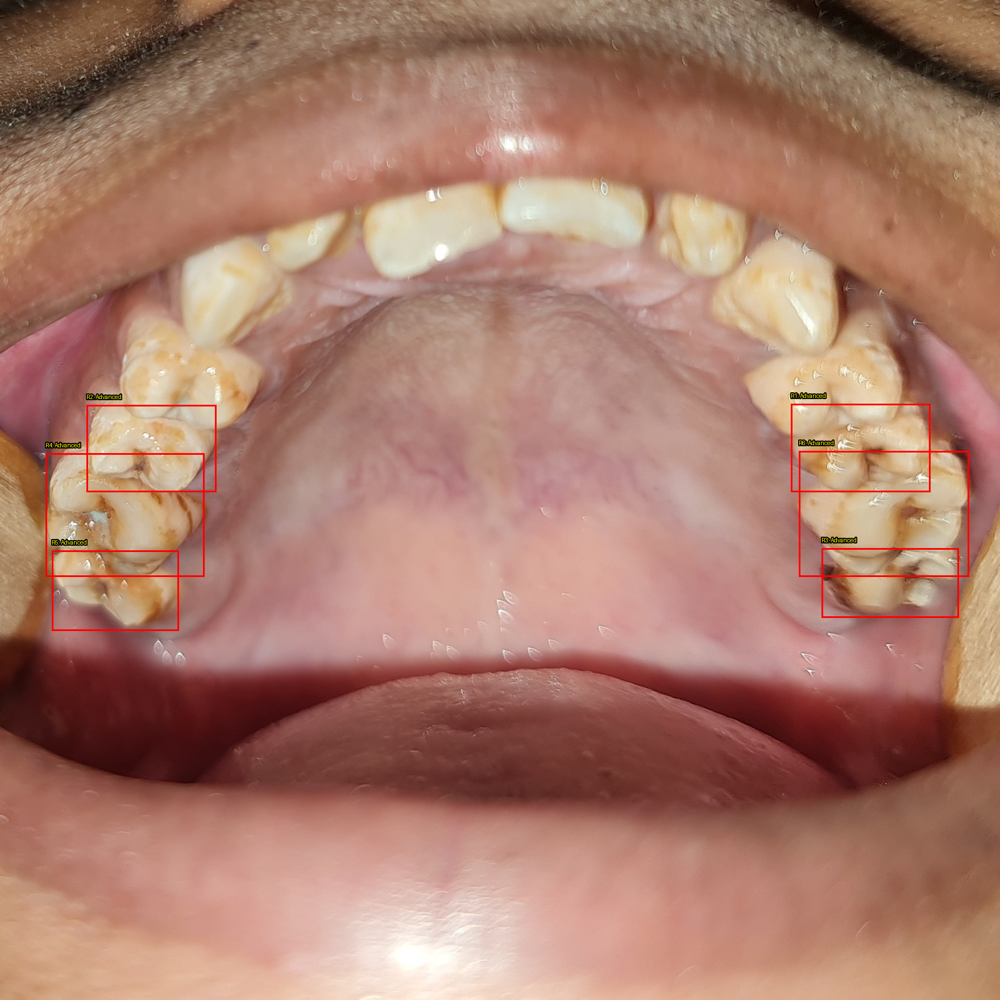

In [ ]:
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path
from IPython.display import display

# Load original image
image = Image.open(test_image).convert("RGB")
draw = ImageDraw.Draw(image)

# Short display labels
label_map = {
    "AdvanceEnamel_Caries": "Advanced",
    "EarlyStageEnamel_Caries": "Early Stage",
    "NoEnamel_Caries": "No Enamel Caries",
    "Uncertain": "Review Required"
}

# Draw detection boxes and severity predictions
for region in final_results["regions"]:
    x1, y1, x2, y2 = region["bounding_box"]

    prediction = region["final_prediction"]
    label = label_map.get(prediction, prediction)

    color = "orange" if prediction == "Uncertain" else "red"

    draw.rectangle(
        [(x1, y1), (x2, y2)],
        outline=color,
        width=3
    )

    text = f"R{region['region']}: {label}"

    # Place label near the box
    text_y = max(0, y1 - 20)

    draw.text(
        (x1, text_y),
        text,
        fill="yellow",
        stroke_width=2,
        stroke_fill="black"
    )

# Save image
save_path = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "Integration/annotated_prediction.jpg"
)

image.save(save_path)

print("Annotated prediction saved successfully!")
print("Location:", save_path)

display(image)

Font loaded successfully!
Improved annotated image saved!
Location: /content/drive/MyDrive/Dental_Caries_Results/Integration/annotated_prediction_improved.jpg


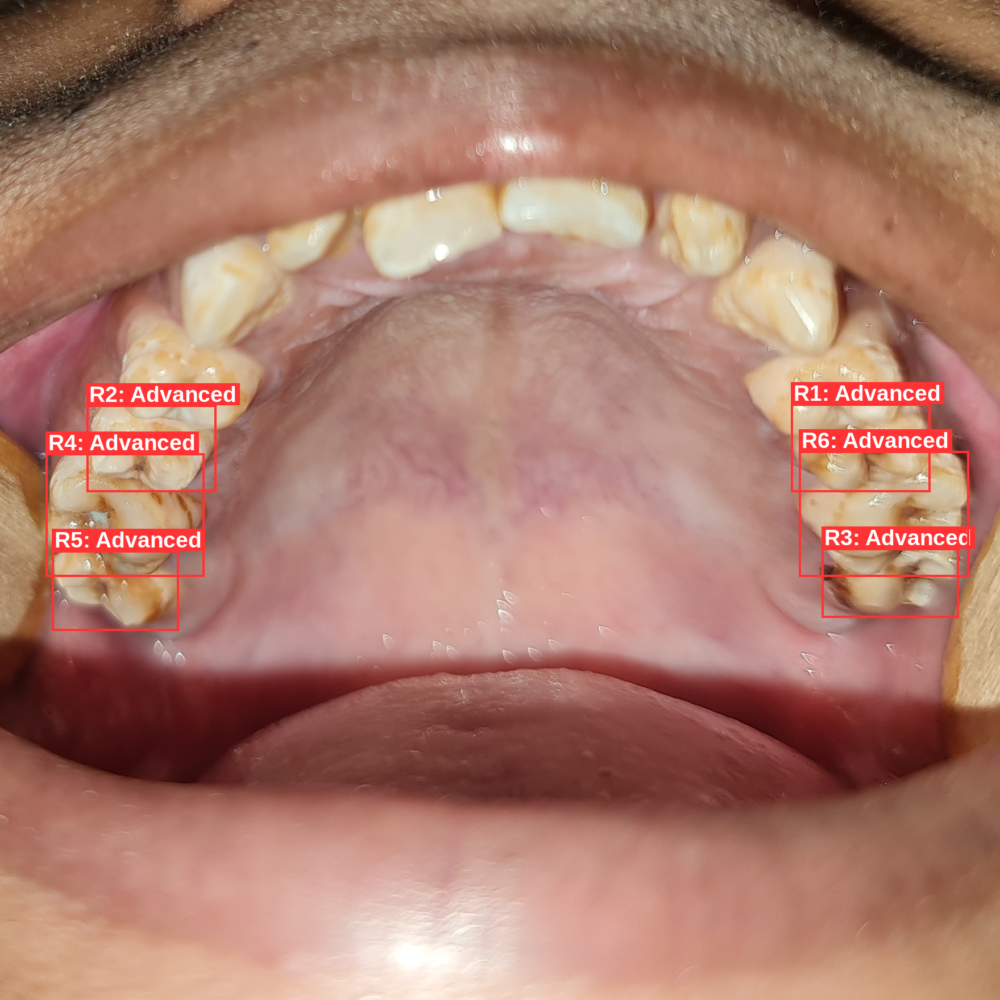

In [ ]:
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path

# Load original image
image = Image.open(test_image).convert("RGB")
draw = ImageDraw.Draw(image)

# Larger font
from PIL import ImageFont

font_size = max(20, image.width // 45)

try:
    font = ImageFont.truetype("DejaVuSans.ttf", font_size)
except OSError:
    try:
        font = ImageFont.truetype(
            "/usr/share/fonts/truetype/liberation2/LiberationSans-Bold.ttf",
            font_size
        )
    except OSError:
        font = ImageFont.load_default(size=font_size)

print("Font loaded successfully!")

# Label colors
colors = {
    "AdvanceEnamel_Caries": "#FF3333",
    "EarlyStageEnamel_Caries": "#FFA500",
    "NoEnamel_Caries": "#22AA55",
    "Uncertain": "#9933FF"
}

labels = {
    "AdvanceEnamel_Caries": "Advanced",
    "EarlyStageEnamel_Caries": "Early Stage",
    "NoEnamel_Caries": "No Enamel Caries",
    "Uncertain": "Review Required"
}

for region in final_results["regions"]:
    x1, y1, x2, y2 = region["bounding_box"]

    prediction = region["final_prediction"]

    color = colors.get(prediction, "white")
    label = labels.get(prediction, prediction)

    text = f"R{region['region']}: {label}"

    # Draw bounding box
    draw.rectangle(
        (x1, y1, x2, y2),
        outline=color,
        width=4
    )

    # Calculate text background
    text_box = draw.textbbox((0, 0), text, font=font)
    text_w = text_box[2] - text_box[0]
    text_h = text_box[3] - text_box[1]

    padding = 5
    text_x = max(0, min(x1, image.width - text_w - 2 * padding))
    text_y = max(0, y1 - text_h - 2 * padding)

    draw.rectangle(
        (
            text_x,
            text_y,
            text_x + text_w + 2 * padding,
            text_y + text_h + 2 * padding
        ),
        fill=color
    )

    draw.text(
        (text_x + padding, text_y + padding - text_box[1]),
        text,
        fill="white",
        font=font
    )

# Save improved output
save_path = Path(
    "/content/drive/MyDrive/Dental_Caries_Results/"
    "Integration/annotated_prediction_improved.jpg"
)

image.save(save_path, quality=95)

print("Improved annotated image saved!")
print("Location:", save_path)

display(image)

In [ ]:
from pathlib import Path

models = {
    "YOLOv8": (
        "/content/drive/MyDrive/Dental_Caries_Results/"
        "YOLOv8_First_Training/weights/best.pt"
    ),
    "MobileNetV2": (
        "/content/drive/MyDrive/Dental_Caries_Results/"
        "MobileNetV2/best_model.keras"
    ),
    "EfficientNet-B0": (
        "/content/drive/MyDrive/Dental_Caries_Results/"
        "EfficientNetB0/best_model.keras"
    )
}

print("MODEL VERIFICATION")
print("------------------")

for name, path in models.items():
    file = Path(path)

    if file.exists():
        size = file.stat().st_size / (1024 * 1024)
        print(f"{name}: FOUND ({size:.2f} MB)")
    else:
        print(f"{name}: MISSING")

MODEL VERIFICATION
------------------
YOLOv8: FOUND (6.20 MB)
MobileNetV2: FOUND (9.23 MB)
EfficientNet-B0: FOUND (16.30 MB)
